In [1]:
!pip install pandas
!pip install numpy
!pip install seaborn
!pip install numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 59.1 MB/s  0:00:00m0:00:01

[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python3 -m pip install --upgrade pip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 66.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 66.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 69.8 MB/s  0:00:00
  Attempting uninstall: pyparsing
    Found existing installation: pyparsing 2.4.7
    Uninstalling pyparsing-2.4.7:
      Successfully uninstalled pyparsing-2.4.7━━ 0/8 [pyparsing]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [seaborn]m7/8 [seaborn]ib]

[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python3 -m pip install --u

In [134]:
!pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 53.3 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 87.7 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [231]:
#import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc

In [185]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [32]:
df_patient = pd.read_csv('patient.csv')

In [33]:
print("Rows:", df_patient.shape[0])
print("Columns:", df_patient.shape[1])

Rows: 200859
Columns: 29


In [4]:
print(df_patient.columns.tolist())

['patientunitstayid', 'patienthealthsystemstayid', 'gender', 'age', 'ethnicity', 'hospitalid', 'wardid', 'apacheadmissiondx', 'admissionheight', 'hospitaladmittime24', 'hospitaladmitoffset', 'hospitaladmitsource', 'hospitaldischargeyear', 'hospitaldischargetime24', 'hospitaldischargeoffset', 'hospitaldischargelocation', 'hospitaldischargestatus', 'unittype', 'unitadmittime24', 'unitadmitsource', 'unitvisitnumber', 'unitstaytype', 'admissionweight', 'dischargeweight', 'unitdischargetime24', 'unitdischargeoffset', 'unitdischargelocation', 'unitdischargestatus', 'uniquepid']


In [5]:
print(df_patient.dtypes)

patientunitstayid              int64
patienthealthsystemstayid      int64
gender                           str
age                              str
ethnicity                        str
hospitalid                     int64
wardid                         int64
apacheadmissiondx                str
admissionheight              float64
hospitaladmittime24              str
hospitaladmitoffset            int64
hospitaladmitsource              str
hospitaldischargeyear          int64
hospitaldischargetime24          str
hospitaldischargeoffset        int64
hospitaldischargelocation        str
hospitaldischargestatus          str
unittype                         str
unitadmittime24                  str
unitadmitsource                  str
unitvisitnumber                int64
unitstaytype                     str
admissionweight              float64
dischargeweight              float64
unitdischargetime24              str
unitdischargeoffset            int64
unitdischargelocation            str
u

df_patient.info()

Missing Values Analysis

In [35]:
# missing = df_patient.isnull().sum()
# missing = missing[missing > 0].sort_values(ascending=False)
# print(missing)

In [10]:
#Missing Percentage

In [36]:
# missing_pct = (
#     df_patient.isnull().mean() * 100
# ).sort_values(ascending=False)

# print(missing_pct[missing_pct > 0])

Target Distribution

In [37]:
# ICU Mortality

print(
    df_patient['unitdischargestatus']
    .value_counts()
)

unitdischargestatus
Alive      189918
Expired     10907
Name: count, dtype: int64


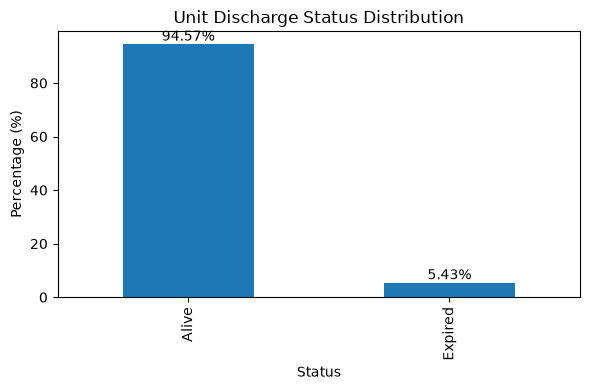

In [38]:
import matplotlib.pyplot as plt

# Unit discharge status
unit_pct = (
    df_patient['unitdischargestatus']
    .value_counts(normalize=True)
    * 100
)

plt.figure(figsize=(6,4))
ax = unit_pct.plot(kind='bar')

plt.title('Unit Discharge Status Distribution')
plt.xlabel('Status')
plt.ylabel('Percentage (%)')

for i, v in enumerate(unit_pct):
    ax.text(i, v, f'{v:.2f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [39]:
# Hospital Discharge Status

print(
    df_patient['hospitaldischargestatus']
    .value_counts()
)

hospitaldischargestatus
Alive      181104
Expired     18004
Name: count, dtype: int64


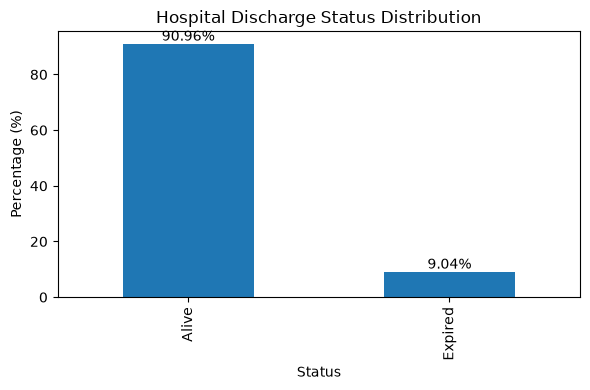

In [40]:
import matplotlib.pyplot as plt

# Hospital discharge status
hospital_pct = (
    df_patient['hospitaldischargestatus']
    .value_counts(normalize=True)
    * 100
)

plt.figure(figsize=(6,4))
ax = hospital_pct.plot(kind='bar')

plt.title('Hospital Discharge Status Distribution')
plt.xlabel('Status')
plt.ylabel('Percentage (%)')

for i, v in enumerate(hospital_pct):
    ax.text(i, v, f'{v:.2f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

Hospital Distribution

In [41]:
print(
    df_patient['hospitalid']
    .nunique()
)

208


In [42]:
df_patient['hospitalid'] \
    .value_counts() \
    .head(20)

hospitalid
73     7059
167    6092
264    5237
420    4679
176    4328
338    4277
243    4243
199    4240
458    3701
443    3656
208    3650
300    3617
188    3601
252    3371
411    3199
165    3053
122    2941
148    2881
171    2807
281    2531
Name: count, dtype: int64

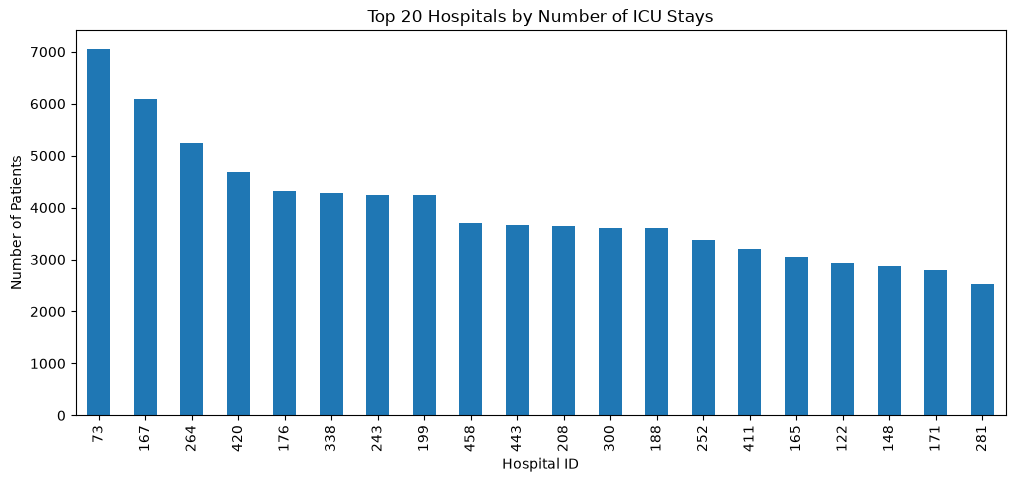

In [43]:
import matplotlib.pyplot as plt

hospital_counts = (
    df_patient['hospitalid']
    .value_counts()
)

plt.figure(figsize=(12,5))

hospital_counts.head(20).plot(kind='bar')

plt.title('Top 20 Hospitals by Number of ICU Stays')
plt.xlabel('Hospital ID')
plt.ylabel('Number of Patients')

plt.show()

In [44]:
print(
    "Hospitals:",
    df_patient['hospitalid'].nunique()
)

print(
    "ICU types:",
    df_patient['unittype'].value_counts()
)

# print(
#     "Regions:",
#     df_patient['region'].value_counts()
# )

Hospitals: 208
ICU types: unittype
Med-Surg ICU    113222
MICU             17465
CCU-CTICU        15290
Neuro ICU        14451
Cardiac ICU      12467
SICU             12181
CSICU             9625
CTICU             6158
Name: count, dtype: int64


Numerical columns → Median imputation

In [45]:
#df_patient['age'] = df_patient['age'].replace('> 89', '90')

df_patient['age'] = df_patient['age'].replace('> 89', '90')

df_patient['age'] = pd.to_numeric(
    df_patient['age'],
    errors='coerce'
)

In [47]:
# df_patient['admissionweight'] = (
#     df_patient['admissionweight']
#     .fillna(df_patient['admissionweight'].median())
# )

# df_patient['admissionheight'] = (
#     df_patient['admissionheight']
#     .fillna(df_patient['admissionheight'].median())
# )

df_patient['age'] = (
    df_patient['age']
    .fillna(df_patient['age'].median())
)

In [48]:
print(df_patient['age'].dtype)

print(df_patient['age'].head(20))

print(df_patient['age'].unique()[:20])

float64
0     70.0
1     52.0
2     52.0
3     68.0
4     71.0
5     71.0
6     77.0
7     25.0
8     82.0
9     90.0
10    81.0
11    59.0
12    43.0
13    19.0
14    19.0
15    67.0
16    73.0
17    59.0
18    63.0
19    61.0
Name: age, dtype: float64
[70. 52. 68. 71. 77. 25. 82. 90. 81. 59. 43. 19. 67. 73. 63. 61. 45. 76.
 50. 72.]


In [49]:
df_patient['uniquepid'].nunique()


139367

In [50]:
df_patient['patienthealthsystemstayid'].nunique()

166355

In [51]:
df_patient.columns.tolist()

['patientunitstayid',
 'patienthealthsystemstayid',
 'gender',
 'age',
 'ethnicity',
 'hospitalid',
 'wardid',
 'apacheadmissiondx',
 'admissionheight',
 'hospitaladmittime24',
 'hospitaladmitoffset',
 'hospitaladmitsource',
 'hospitaldischargeyear',
 'hospitaldischargetime24',
 'hospitaldischargeoffset',
 'hospitaldischargelocation',
 'hospitaldischargestatus',
 'unittype',
 'unitadmittime24',
 'unitadmitsource',
 'unitvisitnumber',
 'unitstaytype',
 'admissionweight',
 'dischargeweight',
 'unitdischargetime24',
 'unitdischargeoffset',
 'unitdischargelocation',
 'unitdischargestatus',
 'uniquepid']

In [52]:
icu_per_patient = (
    df_patient.groupby('uniquepid')['patientunitstayid']
              .nunique()
              .reset_index()
)

icu_per_patient.columns = [
    'uniquepid',
    'icu_stay_count'
]

icu_per_patient.head(20)

,uniquepid,icu_stay_count
0,002-10009,1
1,002-10018,1
2,002-10034,1
3,002-10050,3
4,002-10052,1
5,002-10063,1
6,002-10066,1
7,002-10067,1
8,002-1007,1
9,002-10076,2


Missing Value Analysis

In [53]:
missing_values = pd.DataFrame({
    'missing_count': df_patient.isnull().sum(),
    'missing_percentage': (
        df_patient.isnull().sum() / len(df_patient) * 100
    ).round(2),
    'dtype': df_patient.dtypes
})

missing_values = missing_values.sort_values(
    'missing_percentage',
    ascending=False
)

missing_values

,missing_count,missing_percentage,dtype
dischargeweight,90937,45.27,float64
hospitaladmitsource,49464,24.63,str
apacheadmissiondx,22996,11.45,str
admissionweight,16718,8.32,float64
admissionheight,4215,2.10,float64
ethnicity,2290,1.14,str
hospitaldischargelocation,2033,1.01,str
hospitaldischargestatus,1751,0.87,str
unitadmitsource,1090,0.54,str
unitdischargelocation,334,0.17,str


# Dataset Preprocessing

admissionweight	8.32%	Median imputation

admissionheight	2.10%	Median imputation

In [54]:
df_patient['admissionweight'] = (
    df_patient['admissionweight']
    .fillna(df_patient['admissionweight'].median())
)

df_patient['admissionheight'] = (
    df_patient['admissionheight']
    .fillna(df_patient['admissionheight'].median())
)

In [55]:
categorical_cols = [
    'hospitaladmitsource',
    'apacheadmissiondx',
    'ethnicity',
    'unitadmitsource',
    'gender'
]

for col in categorical_cols:
    df_patient[col] = df_patient[col].fillna('Unknown')

In [56]:
df_patient['age'].value_counts(dropna=False).head(20)

age
90.0    7081
67.0    5078
68.0    4826
72.0    4804
71.0    4764
65.0    4744
66.0    4677
70.0    4571
63.0    4460
62.0    4355
73.0    4333
64.0    4318
69.0    4301
75.0    4280
60.0    4217
61.0    4197
76.0    4170
74.0    4126
77.0    4110
59.0    4068
Name: count, dtype: int64

In [57]:
df_patient['age'] = (
    df_patient['age']
    .replace('> 89', 90)
)

In [58]:
df_patient['apacheadmissiondx'].nunique()

393

Most Common Diagnosis

In [76]:
# Create Target Variable

df_patient['target'] = (
    df_patient['unitdischargestatus']
      .eq('Expired')
      .astype(int)
)

In [77]:
df_patient['target'].value_counts()

target
0    189952
1     10907
Name: count, dtype: int64

In [78]:
df_hospital = pd.read_csv('hospital.csv')

In [79]:
print("Rows:", df_hospital.shape[0])
print("Columns:", df_hospital.shape[1])

Rows: 208
Columns: 4


In [80]:
print(df_hospital.head(10))

   hospitalid numbedscategory teachingstatus   region
0          56            <100              f  Midwest
1          58       100 - 249              f  Midwest
2          59            <100              f  Midwest
3          60            <100              f  Midwest
4          61            <100              f  Midwest
5          63       100 - 249              f  Midwest
6          66       100 - 249              f  Midwest
7          67             NaN              f  Midwest
8          68            <100              f  Midwest
9          69            <100              f  Midwest


# How many hospitals per region

In [82]:
region_hospitals = (
    df_hospital
    .groupby('region')['hospitalid']
    .nunique()
    .reset_index(name='num_hospitals')
    .sort_values('num_hospitals', ascending=False)
)

print(region_hospitals)

      region  num_hospitals
0    Midwest             70
2      South             56
3       West             43
1  Northeast             13


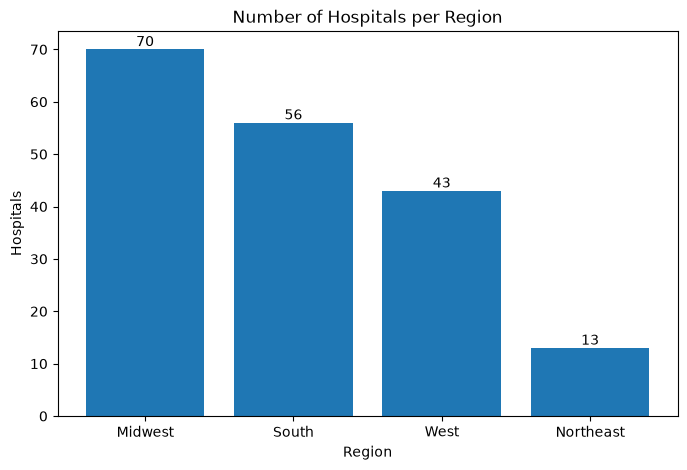

In [83]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    region_hospitals['region'],
    region_hospitals['num_hospitals']
)

plt.title('Number of Hospitals per Region')
plt.xlabel('Region')
plt.ylabel('Hospitals')

# Add numbers on top of bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height)}',
        ha='center',
        va='bottom'
    )

plt.show()

Region

   ↓

Hospitals in that region

   ↓

ICU stays (patientunitstayid) handled by those hospitals

In [91]:
# Hospitals per region

In [84]:
region_hospitals = (
    df_hospital
    .groupby('region')['hospitalid']
    .unique()
)

print(region_hospitals)

region
Midwest      [56, 58, 59, 60, 61, 63, 66, 67, 68, 69, 71, 7...
Northeast    [199, 200, 202, 204, 205, 206, 419, 420, 421, ...
South        [110, 112, 115, 120, 122, 123, 125, 131, 133, ...
West         [146, 148, 151, 152, 154, 155, 156, 157, 158, ...
Name: hospitalid, dtype: object


In [93]:
# Count ICU stays for each region

In [85]:
region_icu_stays = []

for region in df_hospital['region'].unique():

    hospital_ids = df_hospital.loc[
        df_hospital['region'] == region,
        'hospitalid'
    ]

    icu_stays = df_patient.loc[
        df_patient['hospitalid'].isin(hospital_ids),
        'patientunitstayid'
    ].nunique()

    region_icu_stays.append([
        region,
        len(hospital_ids),
        icu_stays
    ])

region_icu_stays = pd.DataFrame(
    region_icu_stays,
    columns=[
        'region',
        'num_hospitals',
        'icu_stays'
    ]
)

print(region_icu_stays)

      region  num_hospitals  icu_stays
0    Midwest             70      65950
1        NaN              0          0
2      South             56      60294
3       West             43      46348
4  Northeast             13      14429


In [86]:
df_hospital['region'].isna().sum()

np.int64(26)

In [87]:
df_hospital = df_hospital.dropna(
    subset=['region']
)

In [88]:
print(
    df_hospital['region']
    .isna()
    .sum()
)

0


In [133]:
# Compute ICU stays per hospital

In [89]:
hospital_load = (
    df_patient
    .groupby('hospitalid')
    ['patientunitstayid']
    .nunique()
    .reset_index(name='icu_stays')
)

In [90]:
hospital_load = hospital_load.merge(
    df_hospital[
        ['hospitalid', 'region']
    ],
    on='hospitalid',
    how='inner'
)

hospital_load.sort_values(
    'icu_stays',
    ascending=False
).head(20)

,hospitalid,icu_stays,region
11,73,7059,Midwest
49,167,6092,West
95,264,5237,Midwest
158,420,4679,Northeast
117,338,4277,Midwest
80,243,4243,South
65,199,4240,Northeast
180,458,3701,South
174,443,3656,South
72,208,3650,South


In [91]:
hospital_stats = (
    df_patient
    .groupby('hospitalid')
    .agg(
        icu_stays=('patientunitstayid','nunique'),
        patients=('uniquepid','nunique'),
        mortality=('target','mean')
    )
    .reset_index()
)

In [92]:
print(hospital_stats)

     hospitalid  icu_stays  patients  mortality
0            56        325       207   0.015385
1            58        321       231   0.015576
2            59        854       463   0.005855
3            60        458       257   0.015284
4            61        233       150   0.021459
..          ...        ...       ...        ...
203         447         39        35   0.076923
204         449       2110      1790   0.075829
205         452        874       713   0.090389
206         458       3701      3010   0.090516
207         459        592       497   0.054054

[208 rows x 4 columns]


In [149]:
# Select top 50 hospitals

In [93]:
top50_hospitals = (
    hospital_stats
    .sort_values(
        'icu_stays',
        ascending=False
    )
    .head(50)
)

selected_hospitals = (
    top50_hospitals['hospitalid']
    .tolist()
)

print(
    "Number of hospitals:",
    len(selected_hospitals)
)

Number of hospitals: 50


In [151]:
# Filter patient data

In [94]:
df_fl = df_patient[
    df_patient['hospitalid']
    .isin(selected_hospitals)
].copy()

In [95]:
print(
    "Hospitals:",
    df_fl['hospitalid'].nunique()
)

print(
    "ICU stays:",
    df_fl['patientunitstayid'].nunique()
)

Hospitals: 50
ICU stays: 132534


In [154]:
# Check class balance per client

In [97]:
client_stats = (
    df_fl
    .groupby('hospitalid')
    ['target']
    .agg(
        patients='count',
        deaths='sum',
        mortality_rate='mean'
    )
)

client_stats.head()

,patients,deaths,mortality_rate
hospitalid,,,
63,1826,49,0.026835
73,7059,227,0.032158
79,1313,98,0.074638
110,2019,124,0.061417
122,2941,248,0.084325


hospitalid-----patients

    |            |    
    
   73  --------------------7059

means:

Hospital 73 handled 7059 ICU stays

NOT:

7059 unique patients

because one patient can have multiple ICU admissions.

In [125]:
print(df_fl.head(20))

    gender   age         ethnicity  \
3     Male  68.0         Caucasian   
7   Female  25.0         Caucasian   
9   Female  90.0         Caucasian   
10  Female  81.0         Caucasian   
11    Male  59.0         Caucasian   
12  Female  43.0  African American   
15    Male  67.0         Caucasian   
17  Female  59.0         Caucasian   
18    Male  63.0         Caucasian   
21    Male  63.0         Caucasian   
22    Male  63.0         Caucasian   
24    Male  45.0         Caucasian   
25    Male  45.0         Caucasian   
26  Female  76.0  African American   
27    Male  50.0           Unknown   
29  Female  80.0         Caucasian   
30    Male  48.0         Caucasian   
31    Male  65.0         Caucasian   
32    Male  81.0         Caucasian   
33    Male  81.0         Caucasian   

                                    apacheadmissiondx  admissionheight  \
3               Sepsis, renal/UTI (including bladder)            180.3   
7   Overdose, sedatives, hypnotics, antipsychotics...

In [159]:
# Create FL dataset with only required columns

In [103]:
features = [
    'gender',
    'age',
    'ethnicity',
    'apacheadmissiondx',
    'admissionheight',
    'admissionweight',
    'hospitaladmitoffset',
    'hospitaladmitsource',
    'unittype',
    'unitadmitsource',
    'unitvisitnumber',
    'unitstaytype'
]

In [104]:
fl_cols = features + [
    'target',
    'hospitalid',
    'uniquepid',
    'patientunitstayid'
]

df_fl = df_fl[fl_cols].copy()

In [169]:
# Total records in FL after preprocessing

In [105]:
print(df_fl.shape)
print(df_fl['hospitalid'].nunique())
print(df_fl['target'].value_counts())

(132534, 16)
50
target
0    125078
1      7456
Name: count, dtype: int64


In [106]:
df_fl[features].isnull().sum()

gender                 0
age                    0
ethnicity              0
apacheadmissiondx      0
admissionheight        0
admissionweight        0
hospitaladmitoffset    0
hospitaladmitsource    0
unittype               0
unitadmitsource        0
unitvisitnumber        0
unitstaytype           0
dtype: int64

In [107]:
print(df_fl)

        gender   age         ethnicity  \
3         Male  68.0         Caucasian   
7       Female  25.0         Caucasian   
9       Female  90.0         Caucasian   
10      Female  81.0         Caucasian   
11        Male  59.0         Caucasian   
...        ...   ...               ...   
200853  Female  79.0  African American   
200854    Male  50.0         Caucasian   
200855  Female  79.0         Caucasian   
200856    Male  73.0  African American   
200858    Male  35.0  African American   

                                        apacheadmissiondx  admissionheight  \
3                   Sepsis, renal/UTI (including bladder)            180.3   
7       Overdose, sedatives, hypnotics, antipsychotics...            172.7   
9                           CHF, congestive heart failure            160.0   
10                               Mitral valve replacement            165.1   
11                        Graft, femoral-popliteal bypass            180.3   
...                        

In [108]:
X = df_fl[features].copy()
y = df_fl['target'].copy()

In [169]:
# Creating Clients

# Each 50 hopitals will be treated as 50 clients

In [126]:
hospital_list = sorted(
    df_fl['hospitalid'].unique()
)

hospital_to_client = {
    hospital: idx + 1
    for idx, hospital in enumerate(hospital_list)
}

In [127]:
print(
    list(hospital_to_client.items())[:10]
)

[(np.int64(63), 1), (np.int64(73), 2), (np.int64(79), 3), (np.int64(110), 4), (np.int64(122), 5), (np.int64(141), 6), (np.int64(142), 7), (np.int64(146), 8), (np.int64(148), 9), (np.int64(152), 10)]


In [172]:
# Create client IDs

In [111]:
df_fl['client_id'] = (
    df_fl['hospitalid']
    .map(hospital_to_client)
)

In [112]:
print(
    df_fl[['hospitalid', 'client_id']]
    .drop_duplicates()
    .head(10)
)

       hospitalid  client_id
3              73          2
9              63          1
14985          79          3
17813         110          4
17816         122          5
24358         142          7
24364         141          6
29808         165         13
29810         152         10
29811         167         14


In [113]:
mapping_table = (
    df_fl[['hospitalid', 'client_id']]
    .drop_duplicates()
    .sort_values('client_id')
)

print(mapping_table)

        hospitalid  client_id
9               63          1
3               73          2
14985           79          3
17813          110          4
17816          122          5
24364          141          6
24358          142          7
29839          146          8
29818          148          9
29810          152         10
29816          154         11
29824          157         12
29808          165         13
29811          167         14
29813          171         15
29827          176         16
58789          183         17
63630          188         18
67232          197         19
71615          199         20
79278          208         21
87513          227         22
90294          243         23
96461          248         24
96457          252         25
102868         264         26
111179         277         27
111160         281         28
111164         283         29
123978         300         30
123976         307         31
123984         310         32
123981    

In [114]:
clients = {}

for client_id in sorted(
    df_fl['client_id'].unique()
):

    clients[client_id] = df_fl[
        df_fl['client_id'] == client_id
    ].copy()

In [177]:
clients[1].head()

,gender,age,ethnicity,apacheadmissiondx,admissionheight,admissionweight,hospitaladmitoffset,hospitaladmitsource,unittype,unitadmitsource,unitvisitnumber,unitstaytype,target,hospitalid,uniquepid,patientunitstayid,client_id
9,Female,90.0,Caucasian,"CHF, congestive heart failure",160.0,89.8,-4,Emergency Department,Med-Surg ICU,Emergency Department,1,admit,0,63,002-54296,141229,1
15,Male,67.0,Caucasian,"CVA, cerebrovascular accident/stroke",190.5,100.0,-1,Direct Admit,Med-Surg ICU,Direct Admit,1,admit,0,63,002-24408,141265,1
17,Female,59.0,Caucasian,"Arrest, respiratory (without cardiac arrest)",165.1,156.6,-1,Operating Room,Med-Surg ICU,Direct Admit,1,admit,0,63,002-9090,141276,1
29,Female,80.0,Caucasian,Transphenoidal surgery,160.0,70.1,-1831,Operating Room,Med-Surg ICU,Operating Room,1,admit,0,63,002-39247,141340,1
41,Female,79.0,Caucasian,"Biopsy, brain",170.2,82.2,-1287,Operating Room,Med-Surg ICU,Operating Room,1,admit,0,63,002-35215,141454,1


In [115]:
clients[1].shape[0]

1826

# EDA of Federated Setting

In [116]:
client_sizes = (
    df_fl
    .groupby('client_id')
    .size()
    .reset_index(name='records')
    .sort_values(
        'records',
        ascending=False
    )
)

print(client_sizes)

    client_id  records
1           2     7059
13         14     6092
25         26     5237
43         44     4679
15         16     4328
34         35     4277
22         23     4243
19         20     4240
49         50     3701
46         47     3656
20         21     3650
29         30     3617
17         18     3601
24         25     3371
39         40     3199
12         13     3053
4           5     2941
8           9     2881
14         15     2807
27         28     2531
40         41     2411
16         17     2135
48         49     2110
45         46     2102
28         29     2097
11         12     2092
33         34     2086
41         42     2078
3           4     2019
42         43     1960
37         38     1937
10         11     1875
30         31     1853
0           1     1826
18         19     1814
6           7     1782
35         36     1758
9          10     1747
23         24     1678
7           8     1612
36         37     1596
5           6     1568
21         

Top 15 clients with the most records

In [117]:
top15_clients = (
    client_sizes
    .head(15)
)

print(top15_clients)

    client_id  records
1           2     7059
13         14     6092
25         26     5237
43         44     4679
15         16     4328
34         35     4277
22         23     4243
19         20     4240
49         50     3701
46         47     3656
20         21     3650
29         30     3617
17         18     3601
24         25     3371
39         40     3199


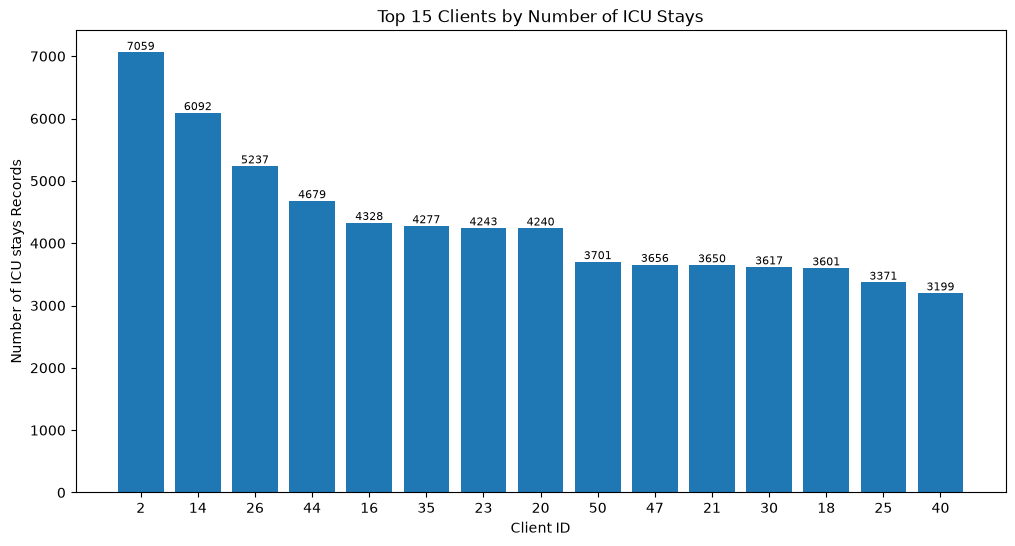

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

bars = plt.bar(
    top15_clients['client_id'].astype(str),
    top15_clients['records']
)

plt.title('Top 15 Clients by Number of ICU Stays')
plt.xlabel('Client ID')
plt.ylabel('Number of ICU stays Records')

# Add values on top
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height)}',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.show()

Create Alive vs Expired counts per client

In [121]:
client_class_dist['Mortality_%'] = (
    client_class_dist['Expired']
    /
    (client_class_dist['Alive']
     + client_class_dist['Expired'])
    * 100
)

#print(client_class_dist.head())

print(client_class_dist)

    client_id  Alive  Expired  Mortality_%
0           1   1777       49     2.683461
1           2   6832      227     3.215753
2           3   1215       98     7.463823
3           4   1895      124     6.141654
4           5   2693      248     8.432506
5           6   1502       66     4.209184
6           7   1637      145     8.136925
7           8   1556       56     3.473945
8           9   2765      116     4.026380
9          10   1665       82     4.693761
10         11   1786       89     4.746667
11         12   1936      156     7.456979
12         13   2918      135     4.421880
13         14   5835      257     4.218647
14         15   2740       67     2.386890
15         16   4200      128     2.957486
16         17   2021      114     5.339578
17         18   3348      253     7.025826
18         19   1705      109     6.008820
19         20   3972      268     6.320755
20         21   3398      252     6.904110
21         22   1445       97     6.290532
22         

In [191]:
# Show mortality percentage for the Top 15 largest clients.

In [122]:
top15_ids = top15_clients['client_id']

top15_mortality = (
    client_class_dist[
        client_class_dist['client_id']
        .isin(top15_ids)
    ]
    .sort_values(
        'Mortality_%',
        ascending=False
    )
)

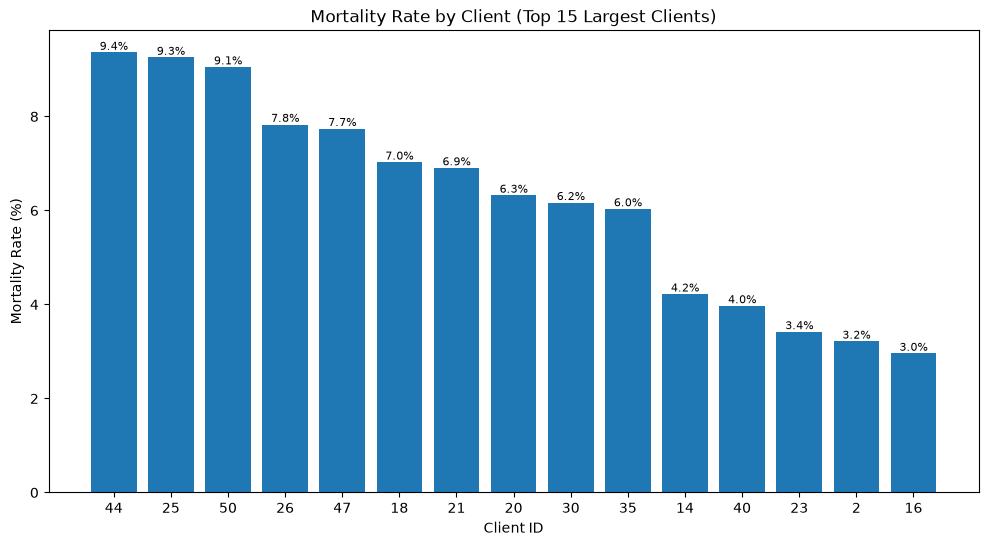

In [123]:
plt.figure(figsize=(12,6))

bars = plt.bar(
    top15_mortality['client_id'].astype(str),
    top15_mortality['Mortality_%']
)

plt.title('Mortality Rate by Client (Top 15 Largest Clients)')
plt.xlabel('Client ID')
plt.ylabel('Mortality Rate (%)')

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{height:.1f}%',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.show()

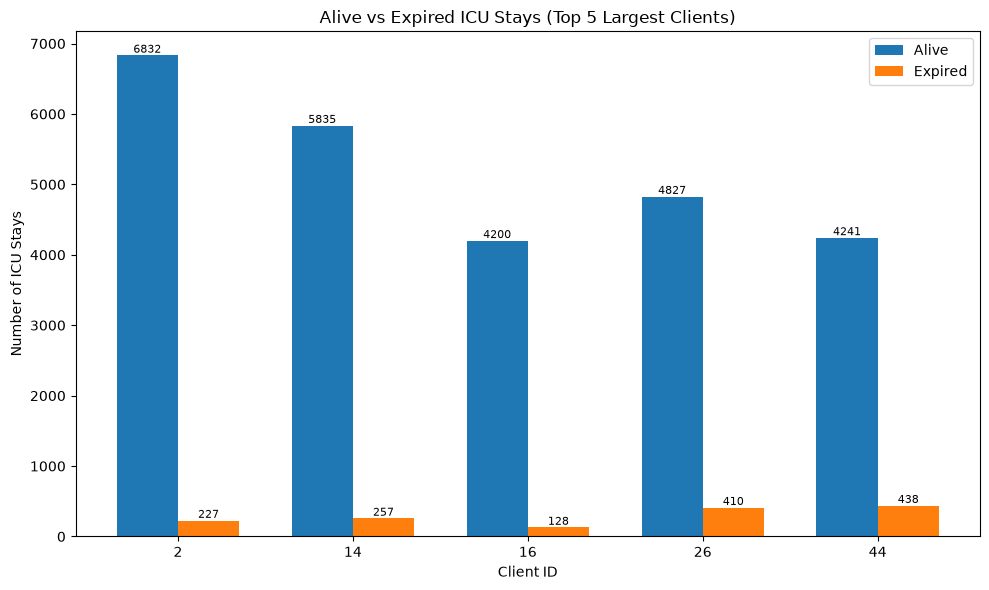

In [128]:
import matplotlib.pyplot as plt
import numpy as np

# Top 5 largest clients
top5_ids = (
    top15_clients
    .head(5)['client_id']
)

top5_data = (
    client_class_dist[
        client_class_dist['client_id']
        .isin(top5_ids)
    ]
    .sort_values(
        'client_id'
    )
)

x = np.arange(
    len(top5_data)
)

width = 0.35

plt.figure(figsize=(10,6))

bars1 = plt.bar(
    x - width/2,
    top5_data['Alive'],
    width,
    label='Alive'
)

bars2 = plt.bar(
    x + width/2,
    top5_data['Expired'],
    width,
    label='Expired'
)

plt.title(
    'Alive vs Expired ICU Stays (Top 5 Largest Clients)'
)

plt.xlabel(
    'Client ID'
)

plt.ylabel(
    'Number of ICU Stays'
)

plt.xticks(
    x,
    top5_data['client_id']
)

plt.legend()

# Alive labels
for bar in bars1:

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{int(bar.get_height())}',
        ha='center',
        va='bottom',
        fontsize=8
    )

# Expired labels
for bar in bars2:

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{int(bar.get_height())}',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.tight_layout()

plt.show()

# Federated Learning Pipeline

In [129]:
# Full dataset
#    ↓
# Global train/test split (80/20)
#    ↓
# Distribute only train set into 50 IID clients
#    ↓
# Federated training
#    ↓
# Evaluate final global model on global test set
#    ↓
# Run FedMIA attacks

# Step 1 — Prepare X and y

In [130]:
X = df_fl[features].copy()
y = df_fl['target'].copy()

print(X.shape)
print(y.shape)
print(y.value_counts())

(132534, 12)
(132534,)
target
0    125078
1      7456
Name: count, dtype: int64


# Step 2 — Global train/test split

In [136]:
from sklearn.model_selection import train_test_split

X_train_global, X_test_global, y_train_global, y_test_global = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [137]:
print(X_train_global.shape)
print(X_test_global.shape)

print(y_train_global.value_counts(normalize=True))
print(y_test_global.value_counts(normalize=True))

(106027, 12)
(26507, 12)
target
0    0.943741
1    0.056259
Name: proportion, dtype: float64
target
0    0.943751
1    0.056249
Name: proportion, dtype: float64


In [173]:
# training set = 132534×0.8=106027.2
# testing set = 132534×0.2=26506.8
# 106027/50=2120.54

# Step 3 — Shuffle training data

In [139]:
from sklearn.utils import shuffle

X_train_global, y_train_global = shuffle(
    X_train_global,
    y_train_global,
    random_state=42
)

In [140]:
#Reset index

X_train_global = X_train_global.reset_index(drop=True)
y_train_global = y_train_global.reset_index(drop=True)

# Step 4 — Split into 50 IID clients

In [143]:
num_clients = 50

client_indices = np.array_split(
    np.arange(len(X_train_global)),
    num_clients
)

# Build client dictionary
clients = {}

for cid, idx in enumerate(client_indices, start=1):

    client_X = X_train_global.iloc[idx].copy()
    client_y = y_train_global.iloc[idx].copy()

    clients[cid] = {
        'X': client_X,
        'y': client_y
    }


# Step 5 — Check client sizes

In [144]:
for cid in range(1, 6):
    print(cid, clients[cid]['X'].shape)

1 (2121, 12)
2 (2121, 12)
3 (2121, 12)
4 (2121, 12)
5 (2121, 12)


# Step 6 — Check class distribution per client

In [145]:
for cid in range(1, 6):
    print(f"Client {cid}")
    print(clients[cid]['y'].value_counts(normalize=True))
    print()

Client 1
target
0    0.944366
1    0.055634
Name: proportion, dtype: float64

Client 2
target
0    0.954738
1    0.045262
Name: proportion, dtype: float64

Client 3
target
0    0.941066
1    0.058934
Name: proportion, dtype: float64

Client 4
target
0    0.947666
1    0.052334
Name: proportion, dtype: float64

Client 5
target
0    0.952852
1    0.047148
Name: proportion, dtype: float64



Visualization 1 — Client sample counts

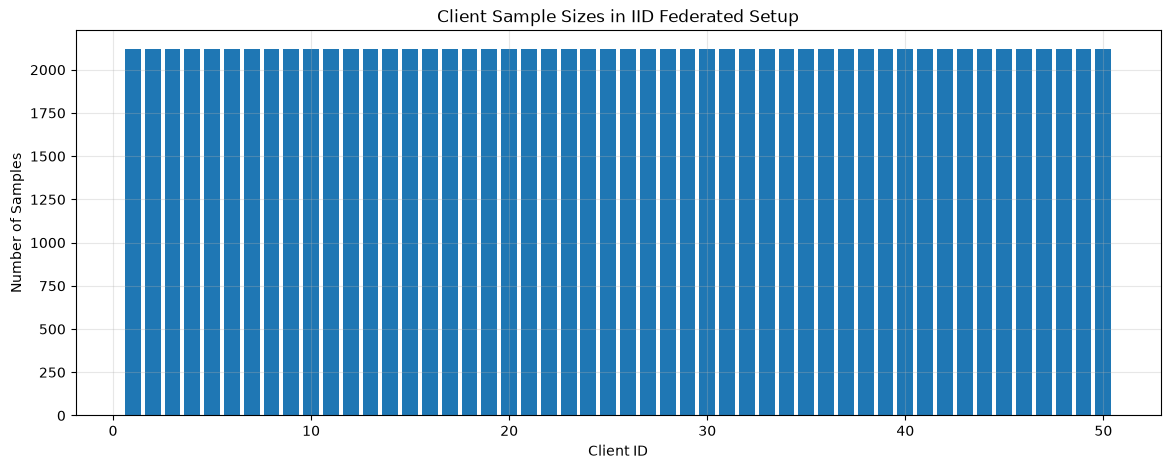

In [148]:
client_sizes = []

for cid in clients:
    client_sizes.append({
        'client_id': cid,
        'size': len(clients[cid]['X'])
    })

size_df = pd.DataFrame(client_sizes)

plt.figure(figsize=(14,5))

plt.bar(
    size_df['client_id'],
    size_df['size']
)

plt.xlabel("Client ID")
plt.ylabel("Number of Samples")
plt.title("Client Sample Sizes in IID Federated Setup")
plt.grid(alpha=0.3)

plt.show()

Visualization 2 — Mortality ratio of random 5 clients

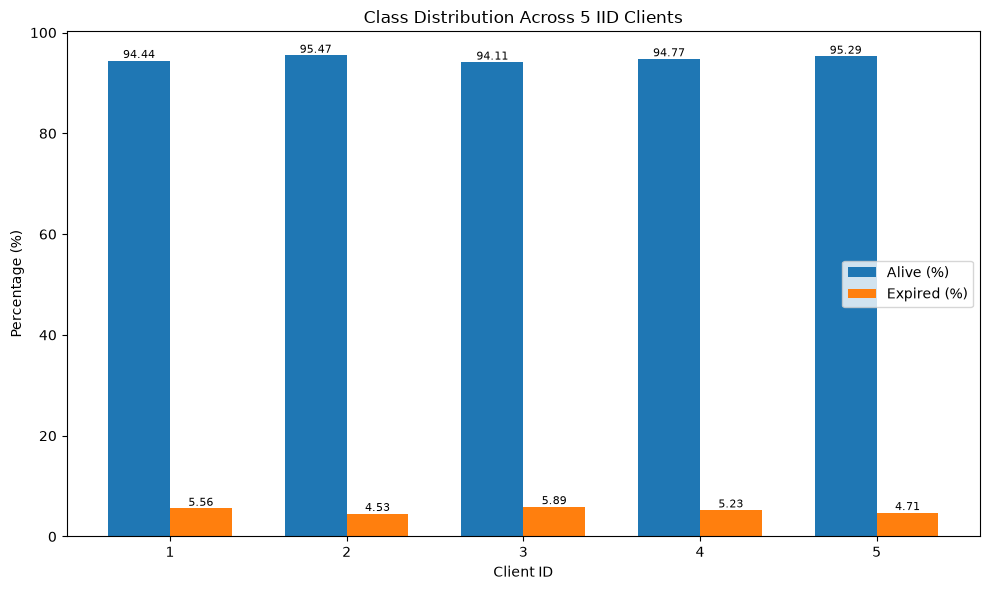

In [152]:
# Select first 5 clients (or random 5)
selected_clients = [1, 2, 3, 4, 5]

alive_rates = []
expired_rates = []

for cid in selected_clients:

    y_client = clients[cid]['y']

    alive_rate = (
        (y_client == 0).mean() * 100
    )

    expired_rate = (
        (y_client == 1).mean() * 100
    )

    alive_rates.append(alive_rate)
    expired_rates.append(expired_rate)

x = np.arange(len(selected_clients))
width = 0.35

plt.figure(figsize=(10,6))

bars1 = plt.bar(
    x - width/2,
    alive_rates,
    width,
    label='Alive (%)'
)

bars2 = plt.bar(
    x + width/2,
    expired_rates,
    width,
    label='Expired (%)'
)

plt.title(
    'Class Distribution Across 5 IID Clients'
)

plt.xlabel('Client ID')
plt.ylabel('Percentage (%)')

plt.xticks(
    x,
    selected_clients
)

plt.legend()

# Add labels
for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{bar.get_height():.2f}',
        ha='center',
        va='bottom',
        fontsize=8
    )

for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{bar.get_height():.2f}',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.tight_layout()
plt.show()

# Verify feature IID

Age mean per client

In [153]:
for cid in range(1, 6):
    print(
        cid,
        clients[cid]['X']['age'].mean()
    )

1 62.73691654879774
2 62.58462989156058
3 63.255068363979255
4 63.09382366808109
5 63.24375294672324


Gender distribution

In [154]:
for cid in range(1, 6):
    print(
        cid,
        clients[cid]['X']['gender'].value_counts(normalize=True)
    )

1 gender
Male      0.532768
Female    0.467232
Name: proportion, dtype: float64
2 gender
Male      0.550684
Female    0.449316
Name: proportion, dtype: float64
3 gender
Male       0.545026
Female     0.454503
Unknown    0.000471
Name: proportion, dtype: float64
4 gender
Male       0.543140
Female     0.455917
Unknown    0.000943
Name: proportion, dtype: float64
5 gender
Male       0.538897
Female     0.460632
Unknown    0.000471
Name: proportion, dtype: float64


Step 7  → Encode categorical features

Step 8  → Scale data

Step 9  → Prepare client tensors

Step 10 → Define MLP model

Step 11 → Local training function

Step 12 → FedAvg aggregation

Step 13 → Global rounds

Step 14 → Evaluate mortality AUC

# Step 7 — Encode categorical features

In [155]:
features = [
    'gender',
    'age',
    'ethnicity',
    'apacheadmissiondx',
    'admissionheight',
    'admissionweight',
    'hospitaladmitoffset',
    'hospitaladmitsource',
    'unittype',
    'unitadmitsource',
    'unitvisitnumber',
    'unitstaytype'
]

categorical_cols = [
    'gender',
    'ethnicity',
    'hospitaladmitsource',
    'unittype',
    'unitadmitsource',
    'unitstaytype'
]

numerical_cols = [
    'age',
    'apacheadmissiondx',
    'admissionheight',
    'admissionweight',
    'hospitaladmitoffset',
    'unitvisitnumber'
]

In [156]:
print(X_train_global.head())

   gender   age         ethnicity  \
0    Male  78.0     Other/Unknown   
1    Male  84.0         Caucasian   
2  Female  53.0  African American   
3    Male  86.0         Caucasian   
4  Female  52.0         Caucasian   

                                   apacheadmissiondx  admissionheight  \
0  Angina, unstable (angina interferes w/quality ...            177.8   
1  Neoplasm-cranial, surgery for (excluding trans...            170.0   
2                                             Anemia            157.5   
3  Cardiac arrest (with or without respiratory ar...            162.6   
4              Overdose, other toxin, poison or drug            167.6   

   admissionweight  hospitaladmitoffset   hospitaladmitsource      unittype  \
0           103.40                -4242  Step-Down Unit (SDU)     CCU-CTICU   
1           107.20                 -192        Operating Room          MICU   
2            57.15                 -201  Emergency Department     Neuro ICU   
3           100.90    

In [159]:
# One-hot encode global train/test

X_train_encoded = pd.get_dummies(
    X_train_global,
    drop_first=True
)

X_test_encoded = pd.get_dummies(
    X_test_global,
    drop_first=True
)

# align 

X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join='left',
    axis=1,
    fill_value=0
)

In [160]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(106027, 445)
(26507, 445)


# Step 8 — Prepare encoded clients

In [161]:
clients_encoded = {}

for cid in clients:

    client_X = pd.get_dummies(
        clients[cid]['X'],
        drop_first=True
    )

    client_X = client_X.reindex(
        columns=X_train_encoded.columns,
        fill_value=0
    )

    clients_encoded[cid] = {
        'X': client_X,
        'y': clients[cid]['y']
    }

In [162]:
print(clients_encoded[1]['X'].shape)
print(X_test_encoded.shape)

(2121, 445)
(26507, 445)


# Step 9 — Scale data

In [164]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_encoded
)

X_test_scaled = scaler.transform(
    X_test_encoded
)

In [165]:
# Scale each client

clients_scaled = {}

for cid in clients_encoded:

    client_X_scaled = scaler.transform(
        clients_encoded[cid]['X']
    )

    clients_scaled[cid] = {
        'X': client_X_scaled,
        'y': clients_encoded[cid]['y'].values
    }

In [168]:
print(clients_scaled[1]['X'].shape)
print(clients_scaled[2]['X'].shape)
print(X_test_scaled.shape)

(2121, 445)
(2121, 445)
(26507, 445)


# Step 10 — Define MLP Model

In [175]:
!pip install torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.2/532.2 MB 99.6 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 110.1 MB/s  0:00:030:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 116.6 MB/s  0:00:010:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.0/206.0 MB 112.0 MB/s  0:00:010:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 113.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 197.7/197.7 MB 114.5 MB/s  0:00:010:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 82.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 95.7 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 90.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 109.6 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 62.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/2

In [176]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [177]:
# Define the Model

class MLP(nn.Module):

    def __init__(self, input_dim):
        super(MLP, self).__init__()

        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

    def forward(self, x):

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))

        return x

In [178]:
# Input dimension
input_dim = X_train_scaled.shape[1]
print(input_dim)

445


In [179]:
# Initialize global model

global_model = MLP(input_dim)

# Step 11 — Local Training Function

In [181]:
import copy
import torch.optim as optim

# Each client trains local copy of global model

def local_train(global_model, X_client, y_client, epochs=3):

    local_model = copy.deepcopy(global_model)

    criterion = nn.BCELoss()

    optimizer = optim.Adam(
        local_model.parameters(),
        lr=0.001
    )

    X_tensor = torch.tensor(
        X_client,
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y_client,
        dtype=torch.float32
    ).view(-1, 1)

    local_model.train()

    for epoch in range(epochs):

        optimizer.zero_grad()

        outputs = local_model(X_tensor)

        loss = criterion(outputs, y_tensor)

        loss.backward()

        optimizer.step()

    return local_model.state_dict()

# Step 12 — FedAvg Aggregation

In [182]:
# This is the server-side aggregation

def fedavg(local_weights):

    avg_weights = copy.deepcopy(local_weights[0])

    for key in avg_weights.keys():

        for i in range(1, len(local_weights)):
            avg_weights[key] += local_weights[i][key]

        avg_weights[key] = avg_weights[key] / len(local_weights)

    return avg_weights

# Step 13 — Federated Training Loop

In [234]:
num_rounds = 20

all_round_global_weights_before = []
all_round_global_weights = []
all_round_local_weights = []

for round_num in range(num_rounds):

    print(f"Round {round_num+1}/{num_rounds}")

    # SAVE GLOBAL MODEL BEFORE CLIENT TRAINING
    all_round_global_weights_before.append(
        copy.deepcopy(global_model.state_dict())
    )

    local_weights = []
    round_local_weights = []

    for cid in clients_scaled:

        X_client = clients_scaled[cid]['X']
        y_client = clients_scaled[cid]['y']

        client_weights = local_train(
            global_model,
            X_client,
            y_client,
            epochs=5
        )

        local_weights.append(client_weights)

        round_local_weights.append(
            copy.deepcopy(client_weights)
        )

    new_global_weights = fedavg(local_weights)

    global_model.load_state_dict(new_global_weights)

    # SAVE GLOBAL MODEL AFTER AGGREGATION
    all_round_global_weights.append(
        copy.deepcopy(new_global_weights)
    )

    all_round_local_weights.append(
        round_local_weights
    )

Round 1/20
Round 2/20
Round 3/20
Round 4/20
Round 5/20
Round 6/20
Round 7/20
Round 8/20
Round 9/20
Round 10/20
Round 11/20
Round 12/20
Round 13/20
Round 14/20
Round 15/20
Round 16/20
Round 17/20
Round 18/20
Round 19/20
Round 20/20


In [235]:
print(len(all_round_local_weights))
print(len(all_round_local_weights[0]))

20
50


# Step 14 — Evaluate Federated Mortality Performance

In [236]:
# Set model to evaluation mode
global_model.eval()

#Convert test data
X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

with torch.no_grad():
    y_prob = global_model(X_test_tensor).numpy().flatten()

In [237]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_test_global,
    y_prob
)

f1 = 2 * precision * recall / (precision + recall + 1e-10)

best_idx = np.argmax(f1)

print("Best threshold:", thresholds[best_idx])
print("Best F1:", f1[best_idx])

Best threshold: 0.15536322
Best F1: 0.2902063543555298


In [238]:
# binary prediction
y_pred = (y_prob >= 0.155).astype(int)


auc = roc_auc_score(y_test_global, y_prob)
print("Federated MLP ROC-AUC:", auc)

Federated MLP ROC-AUC: 0.7651885489463806


In [239]:
print(
    classification_report(
        y_test_global,
        y_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9580    0.9551    0.9565     25016
           1     0.2827    0.2971    0.2897      1491

    accuracy                         0.9181     26507
   macro avg     0.6203    0.6261    0.6231     26507
weighted avg     0.9200    0.9181    0.9190     26507



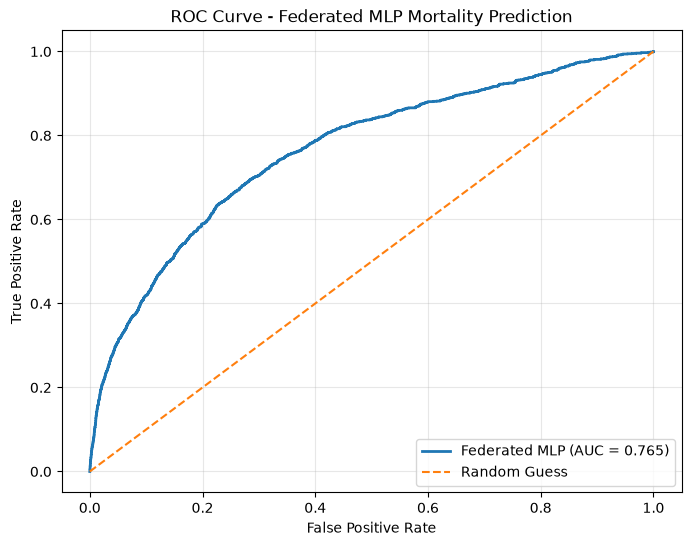

In [241]:
from sklearn.metrics import roc_curve, auc

# ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test_global,
    y_prob
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    lw=2,
    label=f'Federated MLP (AUC = {roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    lw=1.5,
    label='Random Guess'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Federated MLP Mortality Prediction')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()

In [244]:
import pickle

artifacts = {
    "clients_scaled": clients_scaled,
    "clients": clients,
    "X_test_scaled": X_test_scaled,
    "y_test_global": y_test_global,
    "all_round_global_weights_before": all_round_global_weights_before,
    "all_round_global_weights": all_round_global_weights,
    "all_round_local_weights": all_round_local_weights
}

with open("fl_artifacts.pkl", "wb") as f:
    pickle.dump(artifacts, f)

print("Artifacts saved successfully")

Artifacts saved successfully
